In [1]:
import importlib.util
import subprocess
import sys

needed = {"astropy": "astropy", "numpy": "numpy", "matplotlib": "matplotlib", "requests": "requests"}
missing = [package for module, package in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

print("sb theek hh bidoo")


sb theek hh bidoo


In [2]:
from pathlib import Path
from io import BytesIO
from urllib.parse import urlsplit, urlunsplit, parse_qsl, urlencode

import numpy as np
import matplotlib.pyplot as plt
import requests

from astropy.io import fits
from astropy.io.votable import parse as parse_votable
from astropy.visualization import ImageNormalize, PercentileInterval, AsinhStretch
from astropy.wcs import WCS

WORK_DIR = Path("/kaggle/working/planet_x")
WORK_DIR.mkdir(parents=True, exist_ok=True)

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "PlanetX-Kaggle-PoC/1.0 (research notebook)"})
print("Output directory:", WORK_DIR)


Output directory: /kaggle/working/planet_x


In [3]:
RA_DEG = 269.452077
DEC_DEG = 4.693365

# Search radii in degrees. Increase gradually to find an image footprint.
SEARCH_RADII_DEG = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0]

# Requested output cutout width/height in degrees.
CUTOUT_SIZE_DEG = 0.10

COLLECTIONS = [
    "spherex_qr3",
    "spherex_qr3_deep",
    "spherex_qr2",
    "spherex_qr2_deep",
]

print(f"Target: RA={RA_DEG:.8f} deg, Dec={DEC_DEG:.8f} deg")
print("Collections:", COLLECTIONS)


Target: RA=269.45207700 deg, Dec=4.69336500 deg
Collections: ['spherex_qr3', 'spherex_qr3_deep', 'spherex_qr2', 'spherex_qr2_deep']


In [4]:
SIA_ENDPOINT = "https://irsa.ipac.caltech.edu/SIA"

def query_sia(collection, radius_deg):
    params = {
        "COLLECTION": collection,
        "POS": f"CIRCLE {RA_DEG} {DEC_DEG} {radius_deg}",
    }
    response = SESSION.get(SIA_ENDPOINT, params=params, timeout=120)
    response.raise_for_status()
    table = parse_votable(BytesIO(response.content)).get_first_table().to_table(
        use_names_over_ids=True
    )
    return response, table

search_hits = []
search_log = []

for collection in COLLECTIONS:
    for radius in SEARCH_RADII_DEG:
        try:
            response, table = query_sia(collection, radius)
            count = len(table)
            search_log.append((collection, radius, count, response.status_code))
            print(f"{collection:18s} radius={radius:>5} deg -> {count:>4} rows (HTTP {response.status_code})")
            if count:
                search_hits.append((collection, radius, table, response.url))
                break  # keep the smallest radius that returns results for this collection
        except Exception as exc:
            search_log.append((collection, radius, f"ERROR: {exc}", None))
            print(f"{collection:18s} radius={radius:>5} deg -> ERROR: {exc}")

if not search_hits:
    raise RuntimeError(
        "No SPHEREx observations were returned for this target in any documented collection "
        "or search radius. The API connection works, but this coordinate may not be covered "
        "in these releases. Use the IRSA SPHEREx Data Explorer to choose a covered position, "
        "then update RA_DEG and DEC_DEG and rerun from this cell."
    )

print("\nCollections with results:", [hit[0] for hit in search_hits])


spherex_qr3        radius= 0.01 deg ->  123 rows (HTTP 200)
spherex_qr3_deep   radius= 0.01 deg ->    0 rows (HTTP 200)
spherex_qr3_deep   radius= 0.05 deg ->    0 rows (HTTP 200)
spherex_qr3_deep   radius=  0.1 deg ->    0 rows (HTTP 200)
spherex_qr3_deep   radius= 0.25 deg ->    0 rows (HTTP 200)
spherex_qr3_deep   radius=  0.5 deg ->    0 rows (HTTP 200)
spherex_qr3_deep   radius=  1.0 deg ->    0 rows (HTTP 200)
spherex_qr2        radius= 0.01 deg ->    0 rows (HTTP 200)
spherex_qr2        radius= 0.05 deg ->    0 rows (HTTP 200)
spherex_qr2        radius=  0.1 deg ->    0 rows (HTTP 200)
spherex_qr2        radius= 0.25 deg ->    0 rows (HTTP 200)
spherex_qr2        radius=  0.5 deg ->    0 rows (HTTP 200)
spherex_qr2        radius=  1.0 deg ->    0 rows (HTTP 200)
spherex_qr2_deep   radius= 0.01 deg ->    0 rows (HTTP 200)
spherex_qr2_deep   radius= 0.05 deg ->    0 rows (HTTP 200)
spherex_qr2_deep   radius=  0.1 deg ->    0 rows (HTTP 200)
spherex_qr2_deep   radius= 0.25 deg ->  

In [5]:
SELECTED_COLLECTION, SELECTED_RADIUS, observations, query_url = search_hits[0]

print("Selected collection:", SELECTED_COLLECTION)
print("Search radius:", SELECTED_RADIUS, "deg")
print("Query URL:", query_url)
print("Rows:", len(observations))
print("Columns:", observations.colnames)

column_lookup = {name.lower(): name for name in observations.colnames}
if "access_url" not in column_lookup:
    raise KeyError("SIA response has no access_url column.")

access_col = column_lookup["access_url"]
urls = [
    str(value).strip()
    for value in observations[access_col]
    if str(value).strip() and str(value).strip().lower() not in {"--", "nan", "none"}
]

# The IRSA spatial cutout service works on on-prem IBE URLs.
ibe_urls = [url for url in urls if "/ibe/data/" in url.lower() and url.lower().startswith("https://")]

print("Total access URLs:", len(urls))
print("On-prem IBE URLs:", len(ibe_urls))
for i, url in enumerate(ibe_urls[:10]):
    print(f"[{i}] {url}")

if not ibe_urls:
    raise RuntimeError(
        "Rows were found, but no on-prem /ibe/data/ access_url was present. "
        "Inspect the table's cloud_access/access_url fields and use the IRSA Data Explorer download script."
    )

PARENT_FITS_URL = ibe_urls[0]
print("\nChosen parent product:", PARENT_FITS_URL)


Selected collection: spherex_qr3
Search radius: 0.01 deg
Query URL: https://irsa.ipac.caltech.edu/SIA?COLLECTION=spherex_qr3&POS=CIRCLE+269.452077+4.693365+0.01
Rows: 123
Columns: ['s_ra', 's_dec', 'facility_name', 'instrument_name', 'dataproduct_subtype', 'calib_level', 'dataproduct_type', 'energy_bandpassname', 'energy_emband', 'obs_id', 's_resolution', 'em_min', 'em_max', 'em_res_power', 'proposal_title', 'access_url', 'access_format', 'access_estsize', 't_exptime', 's_region', 'obs_collection', 'obs_intent', 'algorithm_name', 'facility_keywords', 'instrument_keywords', 'environment_photometric', 'proposal_id', 'proposal_pi', 'proposal_project', 'target_name', 'target_type', 'target_standard', 'target_moving', 'target_keywords', 'obs_release_date', 's_xel1', 's_xel2', 's_pixel_scale', 'position_timedependent', 't_min', 't_max', 't_resolution', 't_xel', 'obs_publisher_did', 's_fov', 'em_xel', 'pol_states', 'pol_xel', 'cloud_access', 'o_ucd', 'upload_row_id']
Total access URLs: 123
On

In [6]:
def with_query_params(url, params_to_add):
    parts = urlsplit(url)
    params = dict(parse_qsl(parts.query, keep_blank_values=True))
    params.update(params_to_add)
    return urlunsplit((parts.scheme, parts.netloc, parts.path, urlencode(params), parts.fragment))

cutout_url = with_query_params(
    PARENT_FITS_URL,
    {
        "center": f"{RA_DEG},{DEC_DEG}",
        "size": str(CUTOUT_SIZE_DEG),
    },
)

print("Requesting cutout from IRSA...")
print(cutout_url)

cutout_response = SESSION.get(cutout_url, timeout=300)
cutout_response.raise_for_status()

if not cutout_response.content.startswith(b"SIMPLE"):
    content_type = cutout_response.headers.get("Content-Type")
    preview = cutout_response.text[:700]
    raise RuntimeError(
        f"IRSA did not return a FITS primary header (Content-Type={content_type}). "
        f"Response preview:\n{preview}"
    )

SPHEREX_PATH = WORK_DIR / "spherex_irsa_cutout.fits"
SPHEREX_PATH.write_bytes(cutout_response.content)
print("Saved:", SPHEREX_PATH)
print(f"Downloaded size: {SPHEREX_PATH.stat().st_size / 1024**2:.2f} MB")


Requesting cutout from IRSA...
https://irsa.ipac.caltech.edu/ibe/data/spherex/qr3/level2/2026W33_2A/l2b-v27-2026-241/3/level2_2026W33_2A_0594_4D3_spx_l2b-v27-2026-241.fits?center=269.452077%2C4.693365&size=0.1
Saved: /kaggle/working/planet_x/spherex_irsa_cutout.fits
Downloaded size: 3.89 MB


In [7]:
with fits.open(SPHEREX_PATH, memmap=True) as hdul:
    hdul.info()
    print("\nExtension summary:")
    for i, hdu in enumerate(hdul):
        shape = None if hdu.data is None else np.shape(hdu.data)
        print(
            f"HDU {i:>2} | EXTNAME={hdu.header.get('EXTNAME', 'PRIMARY'):<12} "
            f"| shape={str(shape):<20} | BUNIT={hdu.header.get('BUNIT', 'N/A')}"
        )


Filename: /kaggle/working/planet_x/spherex_irsa_cutout.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       276   (58, 59)   float32   
  2  FLAGS         1 ImageHDU       185   (58, 59)   int32   
  3  VARIANCE      1 ImageHDU       119   (58, 59)   float32   
  4  ZODI          1 ImageHDU       122   (58, 59)   float32   
  5  EPSF          1 BinTableHDU     55   451R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [9J, 14J, 252E]   

Extension summary:
HDU  0 | EXTNAME=PRIMARY      | shape=None                 | BUNIT=N/A
HDU  1 | EXTNAME=IMAGE        | shape=(59, 58)             | BUNIT=MJy / sr
HDU  2 | EXTNAME=FLAGS        | shape=(59, 58)             | BUNIT=
HDU  3 | EXTNAME=VARIANCE     | shape=(59, 58)             | BUNIT=MJy2 / sr2
HDU  4 | EXTNAME=ZODI         | shape=(59, 58)             | BUNIT=MJy / sr
HDU  5 | EXTNAME=

In [8]:
with fits.open(SPHEREX_PATH, memmap=True) as hdul:
    primary_header = hdul[0].header.copy()
    print("Primary header:")
    for key in ["ORIGIN", "TELESCOP", "INSTRUME", "DATE-OBS", "OBJECT", "PRODTYPE"]:
        print(f"{key:10s}: {primary_header.get(key, 'Not present')}")

    image_candidates = [
        i for i, hdu in enumerate(hdul)
        if hdu.data is not None
        and np.asarray(hdu.data).ndim == 2
        and str(hdu.header.get("EXTNAME", "")).upper() == "IMAGE"
    ]

    # Fallback only if the named IMAGE extension is absent.
    if not image_candidates:
        image_candidates = [
            i for i, hdu in enumerate(hdul)
            if hdu.data is not None and np.asarray(hdu.data).ndim == 2
        ]

    if not image_candidates:
        raise RuntimeError("No 2-D image extension found in this FITS product.")

    SCIENCE_HDU_INDEX = image_candidates[0]
    science_data = np.asarray(hdul[SCIENCE_HDU_INDEX].data, dtype=np.float32)
    science_header = hdul[SCIENCE_HDU_INDEX].header.copy()

print("Selected HDU:", SCIENCE_HDU_INDEX)
print("EXTNAME:", science_header.get("EXTNAME"))
print("Image shape:", science_data.shape)

provenance = " ".join(
    str(primary_header.get(k, "")) for k in ["ORIGIN", "TELESCOP", "INSTRUME"]
).upper()
print("SPHEREx provenance keyword present:", "SPHEREX" in provenance)
print("SPHEREx collection selected:", SELECTED_COLLECTION)


Primary header:
ORIGIN    : Not present
TELESCOP  : Not present
INSTRUME  : Not present
DATE-OBS  : Not present
OBJECT    : Not present
PRODTYPE  : Not present
Selected HDU: 1
EXTNAME: IMAGE
Image shape: (59, 58)
SPHEREx provenance keyword present: False
SPHEREx collection selected: spherex_qr3


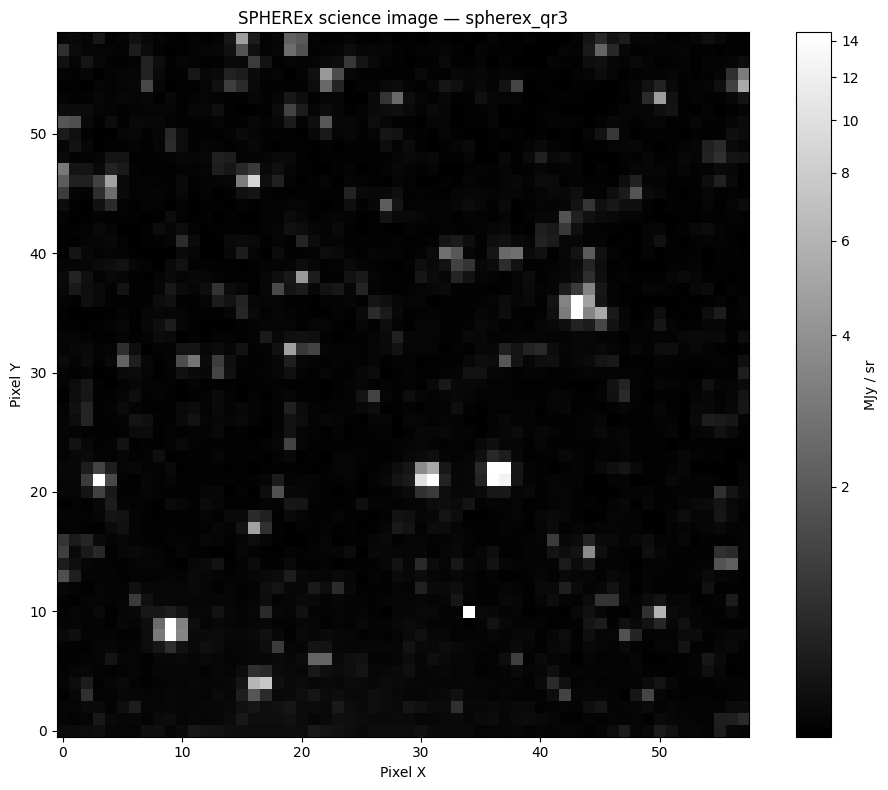

Saved: /kaggle/working/planet_x/spherex_science_image.png


In [9]:
valid = np.isfinite(science_data)
if not valid.any():
    raise RuntimeError("Science image has no finite pixels.")

display_data = np.where(valid, science_data, np.nan)
norm = ImageNormalize(
    display_data,
    interval=PercentileInterval(99.5),
    stretch=AsinhStretch(),
)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(display_data, origin="lower", cmap="gray", norm=norm)
ax.set_title(f"SPHEREx science image — {SELECTED_COLLECTION}")
ax.set_xlabel("Pixel X")
ax.set_ylabel("Pixel Y")
fig.colorbar(im, ax=ax, label=science_header.get("BUNIT", "Pixel value"))
plt.tight_layout()

image_png = WORK_DIR / "spherex_science_image.png"
fig.savefig(image_png, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", image_png)


Celestial WCS available: True


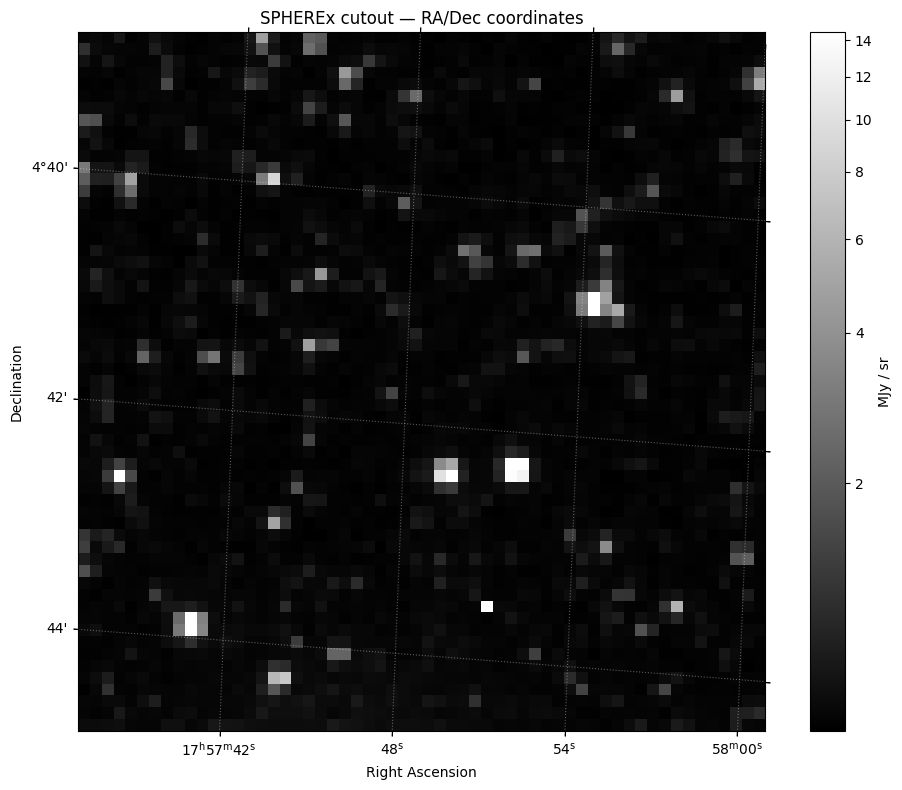

Saved: /kaggle/working/planet_x/spherex_cutout_wcs.png


In [10]:
science_wcs = WCS(science_header)
print("Celestial WCS available:", science_wcs.has_celestial)

if science_wcs.has_celestial:
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection=science_wcs.celestial)
    im = ax.imshow(display_data, origin="lower", cmap="gray", norm=norm)
    ax.set_title("SPHEREx cutout — RA/Dec coordinates")
    ax.set_xlabel("Right Ascension")
    ax.set_ylabel("Declination")
    ax.coords.grid(True, color="white", alpha=0.35, linestyle=":")
    fig.colorbar(im, ax=ax, label=science_header.get("BUNIT", "Pixel value"))
    plt.tight_layout()

    wcs_png = WORK_DIR / "spherex_cutout_wcs.png"
    fig.savefig(wcs_png, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", wcs_png)
else:
    print("No celestial WCS in this extension. Inspect other HDUs/product documentation.")


In [11]:
if science_wcs.has_celestial:
    from astropy.coordinates import SkyCoord
    import astropy.units as u

    target = SkyCoord(RA_DEG * u.deg, DEC_DEG * u.deg, frame="icrs")
    x, y = science_wcs.celestial.world_to_pixel(target)
    print(f"Target maps to pixel x={float(x):.2f}, y={float(y):.2f}")
    inside = (
        np.isfinite(x) and np.isfinite(y)
        and 0 <= x < science_data.shape[1]
        and 0 <= y < science_data.shape[0]
    )
    print("Target falls inside returned image:", inside)
else:
    print("Skipped: celestial WCS is unavailable.")


Target maps to pixel x=28.45, y=29.24
Target falls inside returned image: True


In [12]:
values = science_data[np.isfinite(science_data)]
print("Shape:", science_data.shape)
print("Finite pixels:", values.size)
print("Min:", float(values.min()))
print("Max:", float(values.max()))
print("Mean:", float(values.mean()))
print("Median:", float(np.median(values)))
print("Std:", float(values.std()))

print("\nOutput directory contents:")
for path in sorted(WORK_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name:35s} {path.stat().st_size / 1024**2:.2f} MB")


Shape: (59, 58)
Finite pixels: 3422
Min: -0.7735099792480469
Max: 114.19947052001953
Mean: 0.46198520064353943
Median: 0.2587013244628906
Std: 2.356912612915039

Output directory contents:
spherex_cutout_wcs.png              0.11 MB
spherex_irsa_cutout.fits            3.89 MB
spherex_science_image.png           0.05 MB


## Official references

- [IRSA SPHEREx data access and SIA2 collections](https://caltech-ipac.github.io/spherex-archive-documentation/spherex-data-access/)
- [IRSA SPHEREx cutout service](https://irsa.ipac.caltech.edu/data/SPHEREx/docs/cutout_tool.html)
- [IRSA SPHEREx cutout explanation and MEF extensions](https://irsa.ipac.caltech.edu/onlinehelp/spherex/spherex/cutouts.html)
- [IRSA SPHEREx introductory tutorial](https://caltech-ipac.github.io/irsa-tutorials/spherex-intro/)
- [Astropy FITS documentation](https://docs.astropy.org/en/stable/io/fits/)
- [Astropy WCS documentation](https://docs.astropy.org/en/stable/wcs/)
